# Random Forest classifier: financial hit or bust
Predict **`success`** from the engineered inputs in `../../data/model_data.csv`.

- **1 — Hit:** reported revenue is at least 2.5 times budget.
- **0 — Bust:** reported revenue is below that benchmark.

These are project labels, not audited profit/loss. Averages decision trees to capture nonlinear patterns and interactions. Depth and leaf limits are conservative starting choices. All classifiers use the same chronological split, validation folds, and feature groups. Initial and training-validation-selected settings are compared below.

Run all cells from `Modeling_scripts/success_models/` using `ds6001`. This notebook trains in memory, displays results, and does not write datasets or model files.

Section 4 validates/tunes settings without using the later test data to choose them.

The current model table includes directors' earlier-year rating history, its supporting film count, and a no-history flag. These use retrospective ratings on strictly earlier films; the target movie's rating is still excluded from predictors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.ensemble import RandomForestClassifier

movies = pd.read_csv("../../data/model_data.csv", parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
assert movies["tmdb_id"].is_unique and movies["release_date"].notna().all()
assert movies["success"].isin([0, 1]).all()
print(f"Loaded {len(movies):,} movies | Target: success")

Loaded 6,919 movies | Target: success


## 1. Select predictors
Use movie characteristics and earlier history. Exclude both `success` and `vote_average`, identifiers, and current-movie financial outcomes. Certification and month are categorical; binary flags remain 0/1.

In [2]:
ID_COLUMNS = ["tmdb_id", "imdb_id", "title_tmdb", "release_date"]
TARGET_COLUMNS = ["success", "vote_average"]
NUMERIC_FEATURES = [
    "runtime", "release_year", "n_genres", "imdb_director_count",
    "dir_prior_success_rate_smoothed", "dir_prior_rating_smoothed",
    "dir_prior_rated_films_log1p", "dir_prior_films_log1p",
    "dir_years_active_log1p", "dir_prior_known_films_log1p",
    "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
    "franchise_prior_films_log1p",
]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = [
    "is_sequel", "is_english", "dir_first_film", "dir_no_track_record", "backfill_unavailable", "dir_no_rating_history",
] + [column for column in movies if column.startswith("genre_")]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS))
assert set(movies) == set(ID_COLUMNS + TARGET_COLUMNS + FEATURE_COLUMNS)
assert not set(ID_COLUMNS + TARGET_COLUMNS) & set(FEATURE_COLUMNS)
assert not {"budget", "log_budget", "revenue", "revenue_to_budget", "popularity", "vote_count"} & set(FEATURE_COLUMNS)
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()

X = movies[FEATURE_COLUMNS].copy()
# String conversion is a fixed type conversion, not a learned transformation.
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies["success"].astype(int).copy()
print(f"Predictors: {len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical, {len(BINARY_FEATURES)} binary")

Predictors: 13 numeric, 2 categorical, 24 binary


## 2. Split earlier movies from later movies
Train on approximately the earliest 80%, with later movies for testing. Keep equal release dates together. Inspect class balance before interpreting accuracy.

In [3]:
cutoff = movies.loc[int(len(movies) * 0.8), "release_date"]
train_mask = movies["release_date"].lt(cutoff)
test_mask = ~train_mask
X_train, X_test = X.loc[train_mask].copy(), X.loc[test_mask].copy()
y_train, y_test = y.loc[train_mask].copy(), y.loc[test_mask].copy()
assert len(X_train) > 0 and len(X_test) > 0
assert movies.loc[train_mask, "release_date"].max() < movies.loc[test_mask, "release_date"].min()
assert set(movies.loc[train_mask, "tmdb_id"]).isdisjoint(movies.loc[test_mask, "tmdb_id"])
display(pd.DataFrame([
    ["Training", int(train_mask.sum()), movies.loc[train_mask, "release_date"].min(), movies.loc[train_mask, "release_date"].max()],
    ["Test", int(test_mask.sum()), movies.loc[test_mask, "release_date"].min(), movies.loc[test_mask, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))
assert y_train.nunique() == 2 and y_test.nunique() == 2
class_balance = pd.DataFrame({
    "Training": y_train.value_counts().reindex([0, 1], fill_value=0),
    "Test": y_test.value_counts().reindex([0, 1], fill_value=0),
})
class_balance.index = pd.Index(["Bust (0)", "Hit (1)"], name="Outcome")
display(class_balance)

,Split,Movies,First release,Last release
0,Training,5535,1990-01-12,2017-11-17
1,Test,1384,2017-11-18,2025-12-25


,Training,Test
Outcome,,
Bust (0),3506,909
Hit (1),2029,475


## 3. Fit the classifier and majority baseline
Averages decision trees to capture nonlinear patterns and interactions. Depth and leaf limits are conservative starting choices.

Initial estimator: `RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=10, random_state=42, n_jobs=2)`. Fit imputation, scaling, and one-hot encoding on training data only. Scaling is retained for consistent preprocessing across models; trees do not require it. The baseline always predicts the majority class learned from training.

Use a fixed **0.5 hit-probability threshold**. Do not choose a threshold or settings from test scores.

In [4]:
def make_classifier(columns):
    """Fresh preprocessing and classification for each feature set and split."""
    numeric = [column for column in NUMERIC_FEATURES if column in columns]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in BINARY_FEATURES if column in columns]
    assert set(numeric + categorical + binary) == set(columns)
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
        ("binary", "passthrough", binary),
    ])
    return Pipeline([
        ("preprocessor", preprocessing),
        ("classifier", RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=10, random_state=42, n_jobs=2)),
    ])

initial_model = make_classifier(FEATURE_COLUMNS)
initial_model.fit(X_train, y_train)
initial_train_probability = initial_model.predict_proba(X_train)[:, list(initial_model.classes_).index(1)]
initial_test_probability = initial_model.predict_proba(X_test)[:, list(initial_model.classes_).index(1)]
initial_train_prediction = (initial_train_probability >= 0.5).astype(int)
initial_test_prediction = (initial_test_probability >= 0.5).astype(int)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_prediction = baseline.predict(np.zeros((len(y_test), 1)))
baseline_probability = baseline.predict_proba(np.zeros((len(y_test), 1)))[:, list(baseline.classes_).index(1)]
print("Majority-class baseline prediction:", int(y_train.mode().iloc[0]))

Majority-class baseline prediction: 0


## 4. Validation and tuning: hit F1
Search the existing estimator grid using three expanding chronological folds entirely within the earlier training period. Preprocessing is fitted anew for each candidate/fold. Select by **hit-class F1** (`success = 1`), and show hit precision/recall alongside accuracy, balanced accuracy, macro F1, and ROC AUC.

F1 gives precision and recall equal weight; it is not precision-weighted. Section 4b adds the precision emphasis by requiring a candidate's mean validation precision to meet at least the original model's precision, then maximizing F1 among eligible candidates. Here the settings search still uses threshold 0.5; threshold selection follows below.

Edit `PARAM_GRID` before running. The later test data does not select settings. These folds have already been used in development, so selection scores are exploratory and not independent performance estimates.

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

# Three expanding validation windows entirely within the outer training period.
tuning_dates = movies.loc[train_mask, "release_date"]
assert tuning_dates.index.equals(X_train.index)
unique_tuning_dates = np.sort(tuning_dates.unique())
tuning_splits = []
tuning_periods = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=3).split(unique_tuning_dates), 1):
    fit_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[earlier]).to_numpy())
    validation_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[later]).to_numpy())
    assert tuning_dates.iloc[fit_positions].max() < tuning_dates.iloc[validation_positions].min()
    assert set(fit_positions).isdisjoint(validation_positions)
    tuning_splits.append((fit_positions, validation_positions))
    tuning_periods.append({
        "Fold": fold, "Training movies": len(fit_positions), "Validation movies": len(validation_positions),
        "Training ends": tuning_dates.iloc[fit_positions].max().date(),
        "Validation starts": tuning_dates.iloc[validation_positions].min().date(),
        "Validation ends": tuning_dates.iloc[validation_positions].max().date(),
    })
display(pd.DataFrame(tuning_periods))

PARAM_GRID = {'classifier__max_depth': [6, 12], 'classifier__min_samples_leaf': [5, 10], 'classifier__class_weight': [None, 'balanced']}
TUNING_METRIC = "Hit_F1"  # F1 of the positive class: hit (success = 1).
SCORING = {
    "Hit_F1": make_scorer(f1_score, pos_label=1, zero_division=0),
    "Hit_precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "Hit_recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "Balanced_accuracy": "balanced_accuracy", "Accuracy": "accuracy",
    "Macro_F1": "f1_macro", "ROC_AUC": "roc_auc",
}
for fit_positions, validation_positions in tuning_splits:
    assert y_train.iloc[fit_positions].nunique() == 2
    assert y_train.iloc[validation_positions].nunique() == 2

search = GridSearchCV(
    estimator=make_classifier(FEATURE_COLUMNS), param_grid=PARAM_GRID,
    scoring=SCORING, refit=TUNING_METRIC, cv=tuning_splits,
    n_jobs=1, return_train_score=True, error_score="raise",
)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)
tuning_results = pd.DataFrame({
    "Settings": cv_results["params"].map(lambda params: {key.split("__", 1)[1]: value for key, value in params.items()}),
})
for metric in SCORING:
    tuning_results["Training " + metric] = cv_results["mean_train_" + metric]
    tuning_results["Validation " + metric] = cv_results["mean_test_" + metric]
tuning_results["Validation score std"] = cv_results["std_test_" + TUNING_METRIC]
tuning_results = tuning_results.sort_values("Validation " + TUNING_METRIC, ascending=False, kind="stable")
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100):
    display(tuning_results.reset_index(drop=True).round(4))
print("Selection metric:", TUNING_METRIC)
print("Selected settings:", search.best_params_)
# GridSearchCV already refits the chosen pipeline on the full outer training period.
model = search.best_estimator_
assert set(FEATURE_COLUMNS).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
# Keep 0.5 fixed: this search tunes estimator settings, not the threshold.
train_probability = model.predict_proba(X_train)[:, list(model.classes_).index(1)]
test_probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
train_prediction = (train_probability >= 0.5).astype(int)
test_prediction = (test_probability >= 0.5).astype(int)
assert np.isfinite(test_probability).all()
assert ((test_probability >= 0) & (test_probability <= 1)).all()


,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,1329,1427,1999-12-03,1999-12-10,2006-11-01
1,2,2756,1384,2006-11-01,2006-11-02,2012-03-12
2,3,4140,1395,2012-03-12,2012-03-14,2017-11-17


,Settings,Training Hit_F1,Validation Hit_F1,Training Hit_precision,Validation Hit_precision,Training Hit_recall,Validation Hit_recall,Training Balanced_accuracy,Validation Balanced_accuracy,Training Accuracy,Validation Accuracy,Training Macro_F1,Validation Macro_F1,Training ROC_AUC,Validation ROC_AUC,Validation score std
0,"{'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 5}",0.6529,0.5239,0.5880,0.4912,0.7344,0.5617,0.7337,0.6062,0.7333,0.6191,0.7182,0.6020,0.8077,0.6515,0.0607
1,"{'class_weight': 'balanced', 'max_depth': 6, 'min_samples_leaf': 10}",0.6273,0.5236,0.5604,0.4896,0.7130,0.5635,0.7114,0.6055,0.7108,0.6181,0.6954,0.6010,0.7870,0.6521,0.0606
2,"{'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': 10}",0.7251,0.5200,0.6532,0.4971,0.8151,0.5475,0.7952,0.6086,0.7889,0.6264,0.7768,0.6052,0.8814,0.6552,0.0744
3,"{'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': 5}",0.8142,0.5169,0.7485,0.5002,0.8926,0.5359,0.8684,0.6077,0.8606,0.6278,0.8513,0.6055,0.9447,0.6552,0.0645
4,"{'class_weight': None, 'max_depth': 12, 'min_samples_leaf': 5}",0.5052,0.2637,0.9671,0.6384,0.3429,0.1709,0.6685,0.5609,0.7715,0.6597,0.6784,0.5201,0.9402,0.6574,0.1242
5,"{'class_weight': None, 'max_depth': 12, 'min_samples_leaf': 10}",0.3474,0.2186,0.9210,0.6352,0.2145,0.1377,0.6022,0.5487,0.7252,0.6527,0.5867,0.4965,0.8805,0.6559,0.1230
6,"{'class_weight': None, 'max_depth': 6, 'min_samples_leaf': 5}",0.1866,0.1935,0.9046,0.7085,0.1045,0.1176,0.5491,0.5457,0.6901,0.6537,0.4975,0.4854,0.8077,0.6580,0.1154
7,"{'class_weight': None, 'max_depth': 6, 'min_samples_leaf': 10}",0.1462,0.1783,0.8742,0.6804,0.0812,0.1090,0.5370,0.5414,0.6818,0.6505,0.4752,0.4770,0.7827,0.6572,0.1234


Selection metric: Hit_F1
Selected settings: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 5}


## 4b. Precision guard, feature selection, and threshold selection
Generate predictions for the four feature groups and the initial/selected parameter configurations using only the same three chronological training-period folds. Test hit-probability thresholds **0.30–0.90** in increments of 0.05.

1. Measure the original all-feature model's **mean validation hit precision** at threshold 0.5.
2. Keep candidates whose mean validation precision is at least that reference (or a deliberately specified `MIN_VALIDATION_PRECISION`).
3. Choose the highest mean **hit F1** among eligible candidates; break ties with higher precision, then proximity to threshold 0.5.
4. Refit on all outer training movies and apply the selected threshold to later movies.

This discourages gaining recall by sacrificing validation precision, while F1 prevents choosing precision alone. The precision guard applies to the mean over validation periods, not every period, and it does not guarantee later test precision. All choices reuse already-inspected training folds; a fresh evaluation period or nested chronological validation is needed for independent confirmation. Test outcomes do not determine the guard or threshold.

In [6]:
# Preserve the previous settings-only model for an honest before/after comparison.
settings_model = model
settings_train_probability = train_probability.copy()
settings_test_probability = test_probability.copy()
settings_train_prediction = train_prediction.copy()
settings_test_prediction = test_prediction.copy()

movie_features = (
    ["runtime", "release_year", "n_genres", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p", "dir_years_active_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable"]
company_franchise_features = ["company_films_5yr_log1p", "franchise_prior_films_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

improvement_configurations = {"Initial settings": {}}
initial_parameters = initial_model.get_params()
if any(initial_parameters[key] != value for key, value in search.best_params_.items()):
    improvement_configurations["Settings selected in 4"] = search.best_params_.copy()

# Store only out-of-fold scores. No test rows enter fitting or selection.
selection_rows = []
THRESHOLDS = np.round(np.arange(0.30, 0.901, 0.05), 2)
# None uses the original model's mean validation precision at threshold 0.5.
# Set an explicit requirement here only before examining later test results.
MIN_VALIDATION_PRECISION = None
for setting_name, parameters in improvement_configurations.items():
    for feature_name, columns in feature_versions.items():
        for fold, (fit_positions, validation_positions) in enumerate(tuning_splits, 1):
            candidate = make_classifier(columns).set_params(**parameters)
            candidate.fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
            actual = y_train.iloc[validation_positions]
            assert actual.nunique() == 2
            probability = candidate.predict_proba(X_train.iloc[validation_positions])[:, list(candidate.classes_).index(1)]
            for threshold in THRESHOLDS:
                predicted = (probability >= threshold).astype(int)
                selection_rows.append({
                    "Feature set": feature_name, "Settings": setting_name, "Threshold": threshold, "Fold": fold,
                    "Balanced_accuracy": balanced_accuracy_score(actual, predicted),
                    "Accuracy": accuracy_score(actual, predicted),
                    "Macro_F1": f1_score(actual, predicted, average="macro", zero_division=0),
                    "Hit_F1": f1_score(actual, predicted, pos_label=1, zero_division=0),
                    "Hit_precision": precision_score(actual, predicted, pos_label=1, zero_division=0),
                    "ROC_AUC": roc_auc_score(actual, probability),
                    "Hit_recall": recall_score(actual, predicted, zero_division=0),
                })
selection_metrics = ["Hit_F1", "Hit_precision", "Hit_recall", "Balanced_accuracy", "Accuracy", "Macro_F1", "ROC_AUC"]
selection_keys = ["Feature set", "Settings", "Threshold"]
selection_fold_results = pd.DataFrame(selection_rows)
assert selection_fold_results.groupby(selection_keys)["Fold"].nunique().eq(3).all()
assert np.isfinite(selection_fold_results[selection_metrics].to_numpy()).all()
improvement_summary = selection_fold_results.groupby(selection_keys, sort=False).agg(
    **{metric: (metric, "mean") for metric in selection_metrics},
    Score_std=(TUNING_METRIC, "std"),
).reset_index()
# Precision guard: compare with the original all-feature model, not the majority baseline.
original_validation = improvement_summary.loc[
    improvement_summary["Feature set"].eq("All features")
    & improvement_summary["Settings"].eq("Initial settings")
    & improvement_summary["Threshold"].eq(0.5)
]
assert len(original_validation) == 1
precision_floor = (
    float(original_validation.iloc[0]["Hit_precision"])
    if MIN_VALIDATION_PRECISION is None else float(MIN_VALIDATION_PRECISION)
)
assert 0 <= precision_floor <= 1
improvement_summary["Meets precision floor"] = improvement_summary["Hit_precision"].ge(precision_floor - 1e-12)
improvement_summary["Threshold distance"] = (improvement_summary["Threshold"] - 0.5).abs()
eligible_candidates = improvement_summary.loc[improvement_summary["Meets precision floor"]].sort_values(
    [TUNING_METRIC, "Hit_precision", "Threshold distance"],
    ascending=[False, False, True], kind="stable",
).reset_index(drop=True)
if eligible_candidates.empty:
    raise ValueError("No candidate meets the validation precision requirement. Review the requirement using training-period data only.")
print(f"Minimum mean validation hit precision: {precision_floor:.3f}")
print(f"Eligible candidates: {len(eligible_candidates)} of {len(improvement_summary)}")
with pd.option_context("display.max_columns", None):
    display(eligible_candidates.drop(columns=["Threshold distance"]).head(12).round(4))
winner = eligible_candidates.iloc[0]
assert winner["Hit_precision"] >= precision_floor - 1e-12
print(f"Chosen mean validation hit precision: {winner['Hit_precision']:.3f}; hit F1: {winner['Hit_F1']:.3f}")
selected_feature_set = winner["Feature set"]
selected_feature_columns = feature_versions[selected_feature_set]
selected_parameters = improvement_configurations[winner["Settings"]]
print("Selected feature group:", selected_feature_set)
print("Selected parameter configuration:", winner["Settings"], selected_parameters)
print("Mean selection score (not independent validation):", round(float(winner[TUNING_METRIC]), 4))

model = make_classifier(selected_feature_columns).set_params(**selected_parameters)
model.fit(X_train, y_train)
assert set(selected_feature_columns).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
selected_threshold = float(winner["Threshold"])
print("Selected hit threshold:", selected_threshold)
train_probability = model.predict_proba(X_train)[:, list(model.classes_).index(1)]
test_probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
train_prediction = (train_probability >= selected_threshold).astype(int)
test_prediction = (test_probability >= selected_threshold).astype(int)
assert np.isfinite(test_probability).all()


Minimum mean validation hit precision: 0.635
Eligible candidates: 24 of 104


,Feature set,Settings,Threshold,Hit_F1,Hit_precision,Hit_recall,Balanced_accuracy,Accuracy,Macro_F1,ROC_AUC,Score_std,Meets precision floor
0,All features,Settings selected in 4,0.60,0.2669,0.6578,0.1703,0.5606,0.6587,0.5214,0.6515,0.1193,True
1,Movie characteristics,Settings selected in 4,0.60,0.2579,0.6823,0.1641,0.5598,0.6598,0.5175,0.6489,0.1247,True
2,+ Director history,Settings selected in 4,0.60,0.2579,0.6595,0.1640,0.5585,0.6577,0.5169,0.6499,0.1289,True
3,+ Actor history,Settings selected in 4,0.60,0.2370,0.6420,0.1474,0.5513,0.6525,0.5053,0.6528,0.1133,True
4,All features,Initial settings,0.50,0.2186,0.6352,0.1377,0.5487,0.6527,0.4965,0.6559,0.1507,True
5,+ Actor history,Initial settings,0.50,0.2122,0.6599,0.1333,0.5504,0.6561,0.4949,0.6576,0.1658,True
6,Movie characteristics,Initial settings,0.50,0.2105,0.7225,0.1312,0.5501,0.6562,0.4941,0.6472,0.1507,True
7,+ Director history,Initial settings,0.50,0.2058,0.6580,0.1295,0.5497,0.6563,0.4919,0.6523,0.1734,True
8,All features,Settings selected in 4,0.65,0.1688,0.7295,0.0999,0.5400,0.6505,0.4729,0.6515,0.1300,True
9,All features,Initial settings,0.55,0.1466,0.7490,0.0872,0.5358,0.6486,0.4617,0.6559,0.1479,True


Chosen mean validation hit precision: 0.658; hit F1: 0.267
Selected feature group: All features
Selected parameter configuration: Settings selected in 4 {'classifier__class_weight': 'balanced', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 5}
Mean selection score (not independent validation): 0.2669
Selected hit threshold: 0.6


## 5. Evaluate precision, recall, and F1
**Hit precision:** how many predicted hits really were hits. **Hit recall:** how many actual hits were identified. **Hit F1:** harmonic mean of hit precision and recall, giving both equal weight. Macro F1 is a different metric: it averages F1 across hits and busts.

Keep accuracy, balanced accuracy, ROC AUC, and average precision for context. Inspect the original, settings-only, and precision/F1-selected models side by side. Plots and examples use the final selected model/threshold. The later test period has already been inspected, so treat these results as exploratory. A validation precision guard does not ensure test precision improves.

In [7]:
def classification_scores(name, split, actual, predicted, probability):
    return {
        "Model": name, "Split": split,
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Macro F1": f1_score(actual, predicted, average="macro", zero_division=0),
        "Hit precision": precision_score(actual, predicted, zero_division=0),
        "Hit recall": recall_score(actual, predicted, zero_division=0),
        "Hit F1": f1_score(actual, predicted, pos_label=1, zero_division=0),
        "ROC AUC": roc_auc_score(actual, probability),
        "Average precision": average_precision_score(actual, probability),
    }
results = pd.DataFrame([
    classification_scores("Majority baseline", "Test", y_test, baseline_prediction, baseline_probability),
    classification_scores("Initial Random Forest classifier", "Training", y_train, initial_train_prediction, initial_train_probability),
    classification_scores("Initial Random Forest classifier", "Test", y_test, initial_test_prediction, initial_test_probability),
    classification_scores("Settings-only Random Forest classifier", "Training", y_train, settings_train_prediction, settings_train_probability),
    classification_scores("Settings-only Random Forest classifier", "Test", y_test, settings_test_prediction, settings_test_probability),
    classification_scores("Precision/F1-selected Random Forest classifier", "Training", y_train, train_prediction, train_probability),
    classification_scores("Precision/F1-selected Random Forest classifier", "Test", y_test, test_prediction, test_probability),
])
display(results.round(4))
display(pd.DataFrame(classification_report(
    y_test, test_prediction, labels=[0, 1], target_names=["Bust", "Hit"],
    output_dict=True, zero_division=0,
)).T.round(4))

,Model,Split,Accuracy,Balanced accuracy,Macro F1,Hit precision,Hit recall,Hit F1,ROC AUC,Average precision
0,Majority baseline,Test,0.6568,0.5000,0.3964,0.0000,0.0000,0.0000,0.5000,0.3432
1,Initial Random Forest classifier,Training,0.7164,0.6242,0.6157,0.8410,0.2790,0.4189,0.8571,0.7719
2,Initial Random Forest classifier,Test,0.6756,0.5967,0.5983,0.5430,0.3453,0.4221,0.6755,0.5012
3,Settings-only Random Forest classifier,Training,0.7080,0.6846,0.6850,0.6028,0.5968,0.5998,0.7532,0.6507
4,Settings-only Random Forest classifier,Test,0.5939,0.6079,0.5851,0.4385,0.6526,0.5245,0.6708,0.5023
5,Precision/F1-selected Random Forest classifier,Training,0.6894,0.5896,0.5671,0.7748,0.2154,0.3371,0.7532,0.6507
6,Precision/F1-selected Random Forest classifier,Test,0.6785,0.5934,0.5934,0.5543,0.3221,0.4075,0.6708,0.5023


,precision,recall,f1-score,support
Bust,0.7094,0.8647,0.7794,909.0000
Hit,0.5543,0.3221,0.4075,475.0000
accuracy,0.6785,0.6785,0.6785,0.6785
macro avg,0.6319,0.5934,0.5934,1384.0000
weighted avg,0.6562,0.6785,0.6517,1384.0000


## 6. Inspect mistakes and probabilities
Confusion-matrix rows are actual labels; columns are predictions. A false hit predicts 1 for an actual bust. A missed hit predicts 0 for an actual hit. The example table shows the first ten test movies, not selected best cases. Probabilities are model estimates; their calibration has not been established.

These outputs use the model selected in Section 4b.

/var/folders/s8/tp7sn0_52d556bhs1lz5lcs80000gn/T/ipykernel_17579/615056957.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(prediction_examples.head(10).round(3))


,title_tmdb,release_date,success,hit_probability,predicted_success,correct
5535,Revenge,2017-11-18,0,0.449,0,True
5536,Darkest Hour,2017-11-22,1,0.484,0,False
5537,"Three Billboards Outside Ebbing, Missouri",2017-12-01,1,0.437,0,False
5538,The Shape of Water,2017-12-01,1,0.460,0,False
5539,Wonder Wheel,2017-12-01,0,0.467,0,True
5540,Molly's Game,2017-12-07,0,0.504,0,True
5541,"I, Tonya",2017-12-07,1,0.442,0,False
5542,Ferdinand,2017-12-09,1,0.633,1,True
5543,Star Wars: The Last Jedi,2017-12-13,1,0.834,1,True
5544,Loving Pablo,2017-12-14,1,0.465,0,False


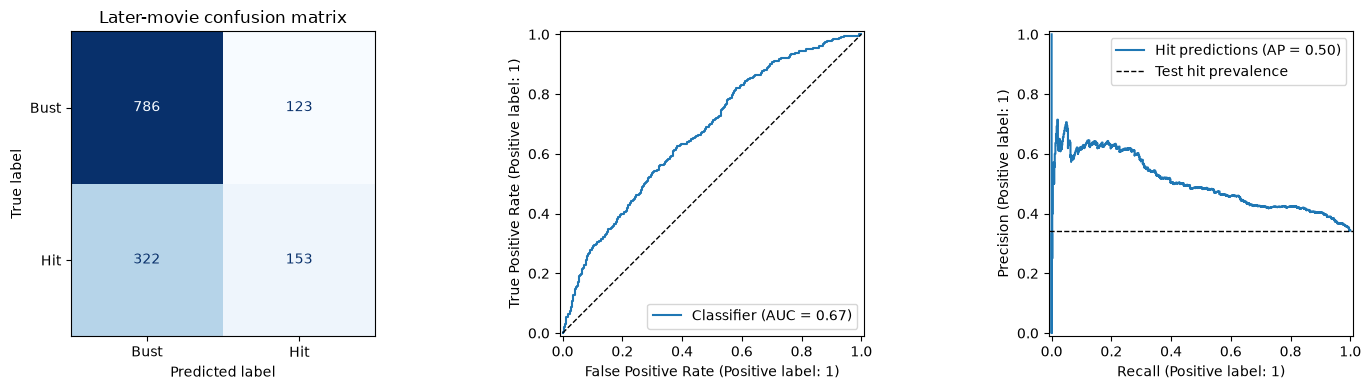

In [8]:
prediction_examples = movies.loc[test_mask, ["title_tmdb", "release_date", "success"]].copy()
prediction_examples["hit_probability"] = test_probability
prediction_examples["predicted_success"] = test_prediction
prediction_examples["correct"] = prediction_examples["success"].eq(test_prediction)
display(prediction_examples.head(10).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, labels=[0, 1], display_labels=["Bust", "Hit"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Later-movie confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[1], name="Classifier")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[2], name="Hit predictions")
axes[2].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label="Test hit prevalence")
axes[2].legend()
plt.tight_layout()
plt.show()

## 7. Compare feature groups within training
Use three expanding chronological validation splits, identical across models and feature versions. Fresh preprocessing is fitted for every fold. Training dates precede validation dates in each split. Compare mean validation ROC AUC, macro F1, and balanced accuracy; no feature version is selected using the later test data.

The comparisons are cumulative: movie characteristics, plus director history, plus actor history, then company/franchise history. They do not isolate individual transformations or prove causation.

This section retains the original estimator settings to isolate the cumulative feature comparison. It does not retune each feature version. The tuning section above searches settings using all features; its selection score is not an independent estimate after selection.

In [9]:
movie_features = (
    ["runtime", "release_year", "n_genres", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p", "dir_years_active_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable"]
company_franchise_features = ["company_films_5yr_log1p", "franchise_prior_films_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

In [10]:
# Split unique dates so equal release dates never appear on both sides.
training_dates = movies.loc[train_mask, "release_date"]
unique_dates = np.sort(training_dates.unique())
validation_splits = []
split_details = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=3).split(unique_dates), 1):
    fit_indices = training_dates.index[training_dates.isin(unique_dates[earlier])]
    validation_indices = training_dates.index[training_dates.isin(unique_dates[later])]
    assert movies.loc[fit_indices, "release_date"].max() < movies.loc[validation_indices, "release_date"].min()
    assert set(fit_indices).isdisjoint(validation_indices)
    assert set(fit_indices).union(validation_indices).issubset(set(X_train.index))
    validation_splits.append((fold, fit_indices, validation_indices))
    split_details.append({
        "Fold": fold, "Training movies": len(fit_indices), "Validation movies": len(validation_indices),
        "Training ends": movies.loc[fit_indices, "release_date"].max().date(),
        "Validation starts": movies.loc[validation_indices, "release_date"].min().date(),
        "Validation ends": movies.loc[validation_indices, "release_date"].max().date(),
    })
display(pd.DataFrame(split_details))

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,1329,1427,1999-12-03,1999-12-10,2006-11-01
1,2,2756,1384,2006-11-01,2006-11-02,2012-03-12
2,3,4140,1395,2012-03-12,2012-03-14,2017-11-17


In [11]:
comparison_rows = []
for version, columns in feature_versions.items():
    for fold, fit_indices, validation_indices in validation_splits:
        assert y_train.loc[fit_indices].nunique() == 2
        assert y_train.loc[validation_indices].nunique() == 2
        candidate = make_classifier(columns)
        candidate.fit(X_train.loc[fit_indices, columns], y_train.loc[fit_indices])
        probability = candidate.predict_proba(X_train.loc[validation_indices, columns])[:, list(candidate.classes_).index(1)]
        predicted = (probability >= 0.5).astype(int)
        metrics = classification_scores(version, "Validation", y_train.loc[validation_indices], predicted, probability)
        comparison_rows.append({"Version": version, "Fold": fold, "Predictors": len(columns), **{key: value for key, value in metrics.items() if key not in ["Model", "Split"]}})
feature_fold_results = pd.DataFrame(comparison_rows)
feature_comparison = feature_fold_results.groupby("Version", sort=False).agg(
    Predictors=("Predictors", "first"),
    Validation_AUC=("ROC AUC", "mean"), AUC_std=("ROC AUC", "std"),
    Validation_macro_F1=("Macro F1", "mean"),
    Validation_hit_F1=("Hit F1", "mean"),
    Validation_hit_precision=("Hit precision", "mean"),
    Validation_hit_recall=("Hit recall", "mean"),
    Validation_balanced_accuracy=("Balanced accuracy", "mean"),
    Validation_accuracy=("Accuracy", "mean"),
)
display(feature_comparison.round(4))
display(feature_fold_results.pivot(index="Version", columns="Fold", values="ROC AUC").reindex(feature_versions).round(4))
assert len(feature_fold_results) == 12

,Predictors,Validation_AUC,AUC_std,Validation_macro_F1,Validation_hit_F1,Validation_hit_precision,Validation_hit_recall,Validation_balanced_accuracy,Validation_accuracy
Version,,,,,,,,,
Movie characteristics,26,0.6472,0.0500,0.4941,0.2105,0.7225,0.1312,0.5501,0.6562
+ Director history,35,0.6523,0.0467,0.4919,0.2058,0.6580,0.1295,0.5497,0.6563
+ Actor history,37,0.6576,0.0423,0.4949,0.2122,0.6599,0.1333,0.5504,0.6561
All features,39,0.6559,0.0406,0.4965,0.2186,0.6352,0.1377,0.5487,0.6527


Fold,1,2,3
Version,,,
Movie characteristics,0.5910,0.6640,0.6865
+ Director history,0.6004,0.6653,0.6911
+ Actor history,0.6126,0.6637,0.6966
All features,0.6156,0.6553,0.6968


## Interpretation and limits
Financial histories use only earlier years and update through time, representing rolling predictions rather than a single forecast at the split date. Retrospective sources do not prove when earlier movies' final outcomes became known. The cohort excludes missing financial values and applies cleaning floors; results do not represent all movies.

Section 4 selects estimator settings using training-period validation. Section 4b additionally selects a threshold using training-period validation; original and settings-only results retain the 0.5 threshold. Compare financial classifiers with one another using the same metrics and splits, not with rating-model MAE/R². Do not repeatedly tune using the already-inspected test period.

The current selection goal is hit F1 subject to a mean validation precision guard. Report hit precision, recall, and F1 together; do not describe F1 itself as giving precision extra weight. Test outcomes never set the precision requirement.